# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Một quy tắc một dòng so với mười mô hình trên bộ dữ liệu lừa đảo trực tuyến phổ biến và độ chính xác gần tuyệt đối thật ra đo điều gì

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** hai notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.

In [1]:
#run once per machine, then comment out
%pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\ASUS\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** ô in đường dẫn của từng file cần có. Nếu tải tự động lỗi hoặc thiếu file, tải tay tại `archive.ics.uci.edu/dataset/967`, chép vào `data/raw/` rồi chạy lại ô này.

In [3]:
FILES = [('https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip', 'phiusiil.zip')]
NEED = ['PhiUSIIL_Phishing_URL_Dataset.csv']
have = lambda: [glob.glob('data/raw/**/' + n, recursive=True) for n in NEED]
if not all(have()):
    for url, name in FILES:
        try: fetch(url, name)
        except Exception as e: print('download failed:', name, e)
    unzip_all()
for n, hit in zip(NEED, have()):
    assert hit, 'missing ' + n + ': download by hand from archive.ics.uci.edu/dataset/967 into data/raw and run this cell again'
    print(n, '->', hit[0], os.path.getsize(hit[0]) // 1024, 'kB')

PhiUSIIL_Phishing_URL_Dataset.csv -> data/raw\PhiUSIIL_Phishing_URL_Dataset.csv 55521 kB


## Bước 1b. Nạp dữ liệu

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số dòng, số cột với mô tả của bộ dữ liệu trong đề cương; nếu khác thì ghi lại con số thật.

In [4]:
# Step 1b: PhiUSIIL Phishing URL data (Prasad and Chandra, 2024): 235,795 web addresses, 54 features of the address and of the page, UCI 2024
# download (one zip, no account): https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip
import pandas as pd, numpy as np, glob
raw = pd.read_csv(
    glob.glob('data/raw/**/PhiUSIIL_Phishing_URL_Dataset.csv', recursive=True)[0],
    encoding='utf-8-sig',
    engine='pyarrow'
)
raw['phishing'] = 1 - raw['label']                       # in the file label 1 means legitimate; here 1 means phishing
print(raw.shape, raw.phishing.value_counts().to_dict()); print(raw[['URL', 'Domain', 'TLD', 'URLLength', 'URLSimilarityIndex', 'IsHTTPS', 'phishing']].head(3).T)

(235795, 57) {0: 134850, 1: 100945}
                                                   0  \
URL                 https://www.southbankmosaics.com   
Domain                      www.southbankmosaics.com   
TLD                                              com   
URLLength                                         31   
URLSimilarityIndex                             100.0   
IsHTTPS                                            1   
phishing                                           0   

                                           1                               2  
URL                 https://www.uni-mainz.de  https://www.voicefmradio.co.uk  
Domain                      www.uni-mainz.de          www.voicefmradio.co.uk  
TLD                                       de                              uk  
URLLength                                 23                              29  
URLSimilarityIndex                     100.0                           100.0  
IsHTTPS                                  

## Bước 2. Làm sạch có nhật ký

- **Làm gì:** kiểm tra miền giá trị, loại dòng lỗi, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [5]:
# Step 2: duplicates, feature groups by the moment each feature becomes available, cleaning log
log = [['raw rows', len(raw)], ['missing cells in numeric columns', int(raw.select_dtypes('number').isna().sum().sum())]]
df = raw.drop_duplicates('URL').copy(); log.append(['unique addresses', len(df)])
df['domain_seen_times'] = df.groupby('Domain').URL.transform('size'); log.append(['addresses whose domain appears more than once', int((df.domain_seen_times > 1).sum())])
df['TLD'] = df.TLD.astype(str).str.lower(); df['row_id'] = np.arange(len(df))
df['starts_https_www'] = df.URL.str.startswith('https://www.').astype(int)      # not a model feature: used to test a one-line rule in RQ3
TEXT = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']; KEY = ['label', 'phishing', 'row_id', 'domain_seen_times', 'starts_https_www']
SHORTCUT = ['URLSimilarityIndex']                        # similarity to a list of known legitimate addresses, built by the authors of the data
ADDRESS = [c for c in ['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation',
           'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
           'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS'] if c in df.columns]      # known before the page is opened
PAGE = [c for c in df.columns if c not in TEXT + KEY + SHORTCUT + ADDRESS]                                              # known only after the page is downloaded
log += [['address features', len(ADDRESS)], ['page features', len(PAGE)], ['phishing addresses', int(df.phishing.sum())], ['top-level domains', df.TLD.nunique()]]
pd.DataFrame(log, columns=['step', 'value']).to_csv('report/table_cleaning_log.csv', index=False); print(log)
df.drop(columns=['FILENAME', 'Title']).to_parquet('data/processed/phishing.parquet', index=False); print(df.shape)

[['raw rows', 235795], ['missing cells in numeric columns', 0], ['unique addresses', 235370], ['addresses whose domain appears more than once', 20535], ['address features', 21], ['page features', 28], ['phishing addresses', 100520], ['top-level domains', 695]]
(235370, 60)


## Bước 2b. Hiểu dữ liệu trước khi đặt câu hỏi

Mười ô dưới đây đọc lại bảng đã làm sạch và trả lời lần lượt: bảng có những cột gì, phân phối ra sao, thiếu ở đâu, có giá trị lạ không, cột nào liên quan tới mục tiêu và mục tiêu khác nhau thế nào giữa các nhóm. **Quy tắc:** sau mỗi ô, nhóm viết một câu nhận xét có số vào dòng Nhận xét. Hình và mô hình chỉ tốt khi nhóm hiểu dữ liệu ở bước này.

### 2b.1 Nạp bảng sạch và xem năm dòng đầu

- **Làm gì:** đọc file parquet, chọn cột mục tiêu và cột nhóm, lấy mẫu cố định để vẽ nhanh.
- **Kiểm tra:** số dòng khớp với nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [6]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#C95B91' if i == highlight else '#F0C6D8' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
E = pd.read_parquet('data/processed/phishing.parquet'); TGT, GRP = 'phishing', 'TLD'
S = E.sample(min(len(E), 50_000), random_state=0)          # a fixed sample keeps every plot fast
NUM = [c for c in S.select_dtypes('number').columns if c != 'row_id' and S[c].nunique() > 1]
print(E.shape[0], 'rows,', E.shape[1], 'columns;', len(NUM), 'numeric columns; target:', TGT, '; group:', GRP); display(E.head(5))

235370 rows, 58 columns; 54 numeric columns; target: phishing ; group: TLD


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,phishing,domain_seen_times,row_id,starts_https_www
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,20,28,119,0,124,1,0,1,0,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,9,8,39,0,217,1,0,1,1,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,2,7,42,2,5,1,0,1,2,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,27,15,22,1,31,1,0,1,3,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,15,34,72,1,85,1,0,1,4,1


### 2b.2 Từ điển dữ liệu

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu, số giá trị khác nhau và một ví dụ của từng cột.
- **Vì sao:** bảng này đi thẳng vào mục Data của bài (số dòng, số cột, ý nghĩa cột).
- **Kiểm tra:** cột nào chỉ có một giá trị hoặc thiếu trên 30% thì ghi lại và cân nhắc bỏ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [7]:
dic = pd.DataFrame({'dtype': E.dtypes.astype(str), 'missing_pct': (100 * E.isna().mean()).round(2), 'unique': E.nunique(),
                    'example': E.iloc[0].astype(str).str.slice(0, 40)})
dic.to_csv('report/table_data_dictionary.csv'); display(dic)

,dtype,missing_pct,unique,example
URL,str,0.0,235370,https://www.southbankmosaics.com
URLLength,int64,0.0,482,31
Domain,str,0.0,220086,www.southbankmosaics.com
DomainLength,int64,0.0,101,24
IsDomainIP,int64,0.0,2,0
TLD,str,0.0,695,com
URLSimilarityIndex,float64,0.0,36350,100.0
CharContinuationRate,float64,0.0,898,1.0
TLDLegitimateProb,float64,0.0,465,0.5229071
URLCharProb,float64,0.0,227293,0.061933179


### 2b.3 Thống kê mô tả các cột số

- **Làm gì:** trung bình, độ lệch chuẩn, các phân vị 1%, 50%, 99%, độ lệch (skew) và tỷ lệ giá trị bằng không.
- **Vì sao:** cột lệch mạnh cần biến đổi log hoặc cắt đuôi trước khi vẽ và trước khi đưa vào mô hình tuyến tính.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
num = S[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T; num['skew'] = S[NUM].skew()
num['zero_pct'] = (100 * (S[NUM] == 0).mean()).round(1); num.to_csv('report/table_numeric_summary.csv'); display(num.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,zero_pct
URLLength,50000.0,34.731,40.756,13.000,17.000,24.000,28.000,34.000,147.000,4.246000e+03,40.531,0.0
DomainLength,50000.0,21.492,9.116,4.000,8.000,16.000,20.000,25.000,57.000,1.050000e+02,2.490,0.0
IsDomainIP,50000.0,0.003,0.052,0.000,0.000,0.000,0.000,0.000,0.000,1.000000e+00,19.312,99.7
URLSimilarityIndex,50000.0,78.298,29.056,0.318,8.119,56.647,100.000,100.000,100.000,1.000000e+02,-0.981,0.0
CharContinuationRate,50000.0,0.846,0.216,0.000,0.250,0.682,1.000,1.000,1.000,1.000000e+00,-1.128,0.0
TLDLegitimateProb,50000.0,0.261,0.252,0.000,0.000,0.006,0.080,0.523,0.523,5.230000e-01,0.070,0.3
URLCharProb,50000.0,0.056,0.011,0.001,0.023,0.051,0.058,0.063,0.074,8.600000e-02,-1.057,0.0
TLDLength,50000.0,2.767,0.601,2.000,2.000,2.000,3.000,3.000,4.000,1.300000e+01,1.828,0.0
NoOfSubDomain,50000.0,1.161,0.595,0.000,0.000,1.000,1.000,1.000,3.000,1.000000e+01,1.773,5.9
HasObfuscation,50000.0,0.002,0.044,0.000,0.000,0.000,0.000,0.000,0.000,1.000000e+00,22.877,99.8


### 2b.4 Giá trị thiếu và dòng trùng

- **Làm gì:** vẽ tỷ lệ thiếu của các cột còn thiếu và đếm dòng trùng.
- **Kiểm tra:** mỗi cột còn thiếu phải có cách xử lý ghi trong nhật ký làm sạch.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
miss = (100 * E.isna().mean()).sort_values(ascending=False); miss = miss[miss > 0].head(12)
print('duplicated rows:', int(S.duplicated().sum()), 'of', len(S), 'sampled rows')
if len(miss): bar_chart(miss.index, miss.values, 'Missing values (%)', 'report/fig_eda_missing.png', highlight=0, fmt='{:.1f}')
else: print('no missing values in the cleaned table')

duplicated rows: 0 of 50000 sampled rows
no missing values in the cleaned table


### 2b.5 Phân phối của mục tiêu

- **Làm gì:** vẽ phân phối cột mục tiêu, thêm thang log nếu là số liên tục, hoặc tỷ lệ từng lớp nếu là nhãn.
- **Vì sao:** lớp hiếm thì dùng PR-AUC thay accuracy; mục tiêu lệch thì báo thêm sai số tương đối.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

class counts in the full table: {0: 134850, 1: 100520}


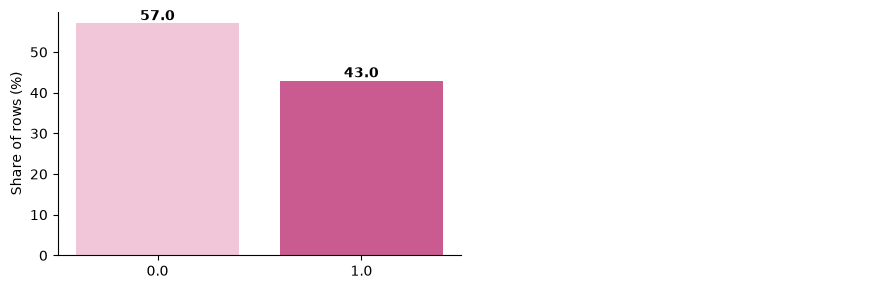

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3)); y = S[TGT].dropna().astype(float)
if y.nunique() <= 10:
    v = y.value_counts(normalize=True).sort_index() * 100; b = ax[0].bar(v.index.astype(str), v.values, color=['#F0C6D8', '#C95B91'][:len(v)]); ax[0].bar_label(b, labels=['%.1f' % x for x in v.values], fontweight='bold'); ax[0].set_ylabel('Share of rows (%)')
    ax[1].axis('off'); print('class counts in the full table:', E[TGT].value_counts().to_dict())
else:
    ax[0].hist(y, bins=50, color='#C95B91'); ax[0].set_ylabel('Rows'); ax[0].set_xlabel(TGT)
    ax[1].hist(np.log1p(y.clip(lower=0)), bins=50, color='#A9C4E2'); ax[1].set_xlabel('log(1 + ' + TGT + ')')
    print(y.describe(percentiles=[.05, .5, .95]).round(3).to_dict())
for a in ax: a.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig('report/fig_eda_target.png', dpi=200); plt.show()

### 2b.6 Phân phối các cột số chính

- **Làm gì:** tám biểu đồ tần suất, đã cắt 1% hai đầu để nhìn rõ phần chính.
- **Kiểm tra:** cột có hai đỉnh thường ứng với hai chế độ vận hành, nên tách ra khi phân tích.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

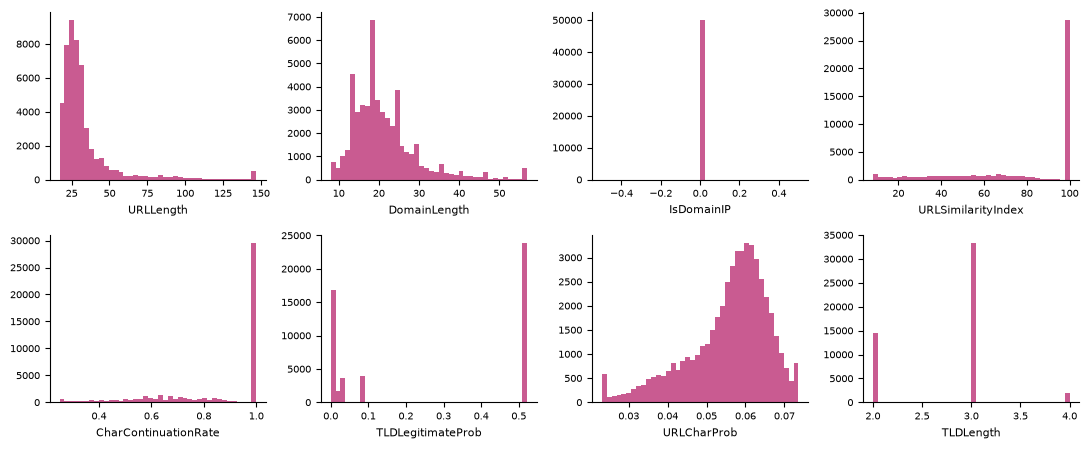

In [11]:
cols = [c for c in NUM if c != TGT][:8]; fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for a, c in zip(axes.ravel(), cols):
    x = S[c].dropna().astype(float); x = x.clip(x.quantile(.01), x.quantile(.99)); a.hist(x, bins=40, color='#C95B91'); a.set_xlabel(c, fontsize=8); a.spines[['top', 'right']].set_visible(False); a.tick_params(labelsize=7)
for a in axes.ravel()[len(cols):]: a.axis('off')
fig.tight_layout(); fig.savefig('report/fig_eda_distributions.png', dpi=200); plt.show()

### 2b.7 Giá trị ngoại lai

- **Làm gì:** tỷ lệ dòng nằm ngoài 1,5 lần khoảng tứ phân vị của từng cột.
- **Vì sao:** ngoại lai là lỗi đo thì loại và ghi nhật ký; là hiện tượng thật (đỉnh tải, sự cố) thì giữ và nêu trong bài.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [12]:
N_ = S[NUM].astype(float); q1, q3 = N_.quantile(.25), N_.quantile(.75); iqr = q3 - q1
out = (100 * ((N_ < q1 - 1.5 * iqr) | (N_ > q3 + 1.5 * iqr)).mean()).sort_values(ascending=False).round(2).rename('outside_1.5_IQR_pct')
out.to_csv('report/table_outliers.csv'); display(out.head(12).to_frame())

,outside_1.5_IQR_pct
NoOfSubDomain,24.18
Pay,23.47
DegitRatioInURL,22.13
NoOfDegitsInURL,22.13
IsHTTPS,21.77
NoOfEmptyRef,16.58
NoOfiFrame,14.54
HasTitle,14.00
NoOfURLRedirect,13.15
Bank,12.49


### 2b.8 Cột nào liên quan tới mục tiêu

- **Làm gì:** tương quan hạng Spearman giữa từng cột số và mục tiêu, vẽ mười cột mạnh nhất.
- **Vì sao:** đây là dự báo sớm về đặc trưng quan trọng; cột tương quan gần 1 có thể là rò rỉ và phải kiểm tra ý nghĩa.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,0
label,-1.000
starts_https_www,-0.979
URLSimilarityIndex,-0.944
NoOfImage,-0.843
NoOfExternalRef,-0.842
LineOfCode,-0.841
NoOfSelfRef,-0.830
NoOfJS,-0.822
NoOfCSS,-0.804
HasSocialNet,-0.787


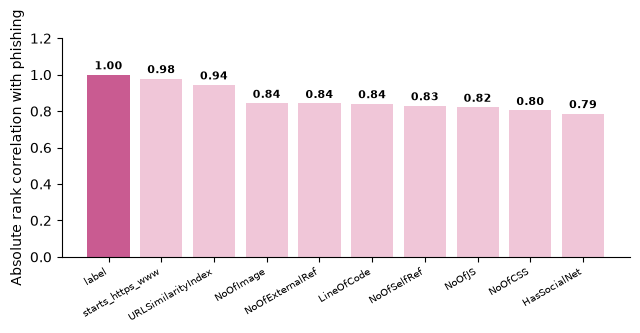

In [13]:
others = [c for c in NUM if c != TGT]
cor = S[others].astype(float).corrwith(S[TGT].astype(float), method='spearman').dropna(); cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(10)
cor.rename('spearman_with_target').to_csv('report/table_eda_correlation.csv'); display(cor.round(3).to_frame())
if len(cor) and cor.abs().max() > 0: bar_chart(cor.index, cor.abs().values, 'Absolute rank correlation with ' + TGT, 'report/fig_eda_correlation.png', highlight=0, fmt='{:.2f}')

### 2b.9 Các cột mạnh có trùng thông tin không

- **Làm gì:** ma trận tương quan giữa mục tiêu và bảy cột mạnh nhất.
- **Kiểm tra:** hai cột tương quan trên 0,95 với nhau thì chỉ cần giữ một khi giải thích kết quả.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

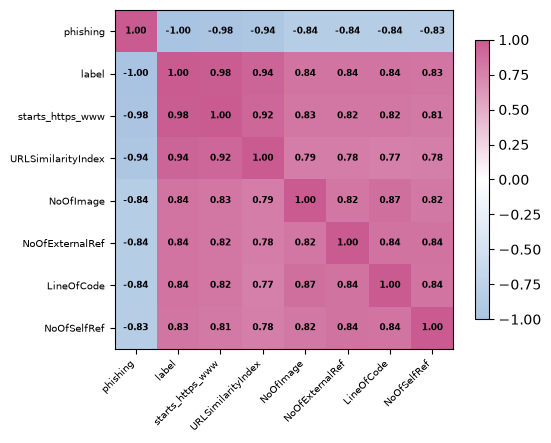

In [14]:
top = [TGT] + list(cor.index[:7]); m = S[top].astype(float).corr(method='spearman'); fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(m, cmap=__import__('matplotlib.colors').colors.LinearSegmentedColormap.from_list('pinkblue', ['#A9C4E2', '#FFFFFF', '#C95B91']), vmin=-1, vmax=1); ax.set_xticks(range(len(top))); ax.set_yticks(range(len(top))); ax.set_xticklabels(top, rotation=45, ha='right', fontsize=7); ax.set_yticklabels(top, fontsize=7)
for i in range(len(top)):
    for j in range(len(top)): ax.text(j, i, '%.2f' % m.iloc[i, j], ha='center', va='center', fontsize=6.5, fontweight='bold')
fig.colorbar(im, shrink=0.8); fig.tight_layout(); fig.savefig('report/fig_eda_heatmap.png', dpi=200); plt.show()

### 2b.10 Mục tiêu theo nhóm

- **Làm gì:** số dòng, trung bình, trung vị và độ lệch chuẩn của mục tiêu theo cột nhóm, kèm hình.
- **Vì sao:** khác biệt giữa các nhóm là gợi ý trực tiếp cho RQ1 và cho cách chia dữ liệu ở Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,rows,mean,median,std
TLD,,,,
com,112382,0.388,0.0,0.487
org,18792,0.121,0.0,0.326
net,7076,0.435,0.0,0.496
app,6467,0.978,1.0,0.146
uk,6395,0.050,0.0,0.219
co,5408,0.915,1.0,0.278
io,4174,0.897,1.0,0.305
de,3994,0.171,0.0,0.377
ru,3870,0.770,1.0,0.421


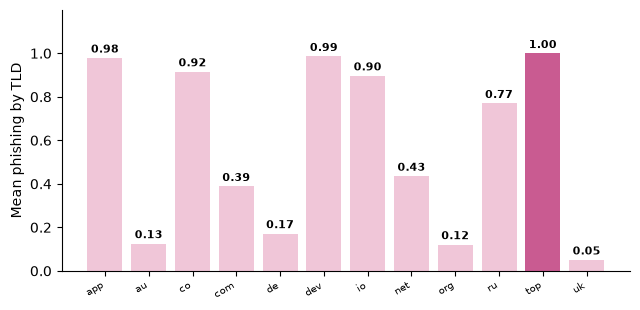

In [15]:
g = E.assign(_t=E[TGT].astype(float)).groupby(GRP)['_t'].agg(['size', 'mean', 'median', 'std']).rename(columns={'size': 'rows'})
g.to_csv('report/table_eda_by_group.csv'); display(g.sort_values('rows', ascending=False).head(15).round(3))
gg = g.sort_values('rows', ascending=False).head(12).sort_index()
if gg['mean'].min() >= 0 and gg['mean'].max() > 0: v, lab, f = nice(gg['mean'], 'Mean ' + TGT + ' by ' + GRP); bar_chart(gg.index.astype(str), v, lab, 'report/fig_eda_by_group.png', highlight=int(v.argmax()), fmt=f)

### Tổng hợp EDA

| Quan sát (có số) | Bằng chứng (bảng, hình) | Ảnh hưởng tới câu hỏi nào | Việc cần làm |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |
| | | | |

## Bước 3. Truy vấn dữ liệu bằng SQL

- **Làm gì:** ghi mọi truy vấn vào `sql/queries.sql`, rồi chạy **từng truy vấn một ô** để đọc kết quả và viết nhận xét.
- **Vì sao:** RQ1 được trả lời bằng bảng số; bảng `feat` là đầu vào của Notebook B.
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [16]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE ph AS SELECT * FROM 'data/processed/phishing.parquet';
-- Q1: the two classes side by side
SELECT phishing, COUNT(*) AS addresses, AVG(URLLength) AS mean_length, 100.0 * AVG(IsHTTPS) AS https_pct, 100.0 * AVG(starts_https_www) AS starts_https_www_pct, AVG(NoOfSubDomain) AS subdomains, AVG(URLSimilarityIndex) AS similarity_index,
       100.0 * AVG(HasTitle) AS has_title_pct, AVG(NoOfImage) AS images FROM ph GROUP BY 1 ORDER BY 1;
-- Q2: top-level domains ranked by volume, with their share of phishing
SELECT TLD, COUNT(*) AS addresses, 100.0 * AVG(phishing) AS phishing_pct, RANK() OVER (ORDER BY COUNT(*) DESC) AS rank FROM ph GROUP BY 1 ORDER BY 4 LIMIT 15;
-- Q3: how well the similarity index alone separates the classes (bands of 10 points)
SELECT CAST(FLOOR(URLSimilarityIndex / 10) * 10 AS INT) AS similarity_from, COUNT(*) AS addresses, 100.0 * AVG(phishing) AS phishing_pct,
       100.0 * SUM(COUNT(*)) OVER (ORDER BY CAST(FLOOR(URLSimilarityIndex / 10) * 10 AS INT)) / SUM(COUNT(*)) OVER () AS cumulative_pct FROM ph GROUP BY 1 ORDER BY 1;
-- Q4: model table (numeric features and the keys needed for the splits)
CREATE OR REPLACE TABLE feat AS SELECT * EXCLUDE (URL) FROM ph;
SELECT phishing, COUNT(*) AS n FROM feat GROUP BY 1;
"""
open('sql/queries.sql', 'w').write(SQL)

1297

In [17]:
import duckdb
con = duckdb.connect(); QN = 0
def run(stmt):                                           # runs one statement; a SELECT is shown, saved and plotted when the result is small
    global QN
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if not body.upper().startswith(('SELECT', 'WITH', 'SUMMARIZE')): con.execute(stmt); print('done'); return None
    QN += 1; r = con.execute(stmt).df(); r.to_csv('report/table_q%d.csv' % QN, index=False); display(r.head(15))
    numc = [c for c in r.columns[1:] if pd.api.types.is_numeric_dtype(r[c])]
    if 2 <= len(r) <= 30 and numc and r[numc[0]].notna().all() and r[numc[0]].min() >= 0 and r[numc[0]].max() > 0:
        v, lab, f = nice(r[numc[0]], numc[0]); bar_chart(r.iloc[:, 0].astype(str), v, lab, 'report/fig_q%d.png' % QN, highlight=int(v.argmax()), fmt=f)
    return r

### Step 3: sql/queries.sql

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [18]:
r = run(r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE ph AS SELECT * FROM 'data/processed/phishing.parquet';""")

done


### Q1: the two classes side by side

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,phishing,addresses,mean_length,https_pct,starts_https_www_pct,subdomains,similarity_index,has_title_pct,images
0,0,134850,26.228610,100.000000,100.000000,1.161661,100.000000,99.875417,44.946600
1,1,100520,45.702845,49.122563,2.432352,1.169379,49.651466,67.723836,0.864206


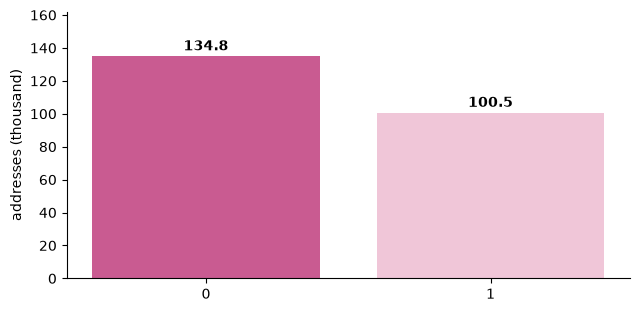

In [19]:
r = run(r"""-- Q1: the two classes side by side
SELECT phishing, COUNT(*) AS addresses, AVG(URLLength) AS mean_length, 100.0 * AVG(IsHTTPS) AS https_pct, 100.0 * AVG(starts_https_www) AS starts_https_www_pct, AVG(NoOfSubDomain) AS subdomains, AVG(URLSimilarityIndex) AS similarity_index,
       100.0 * AVG(HasTitle) AS has_title_pct, AVG(NoOfImage) AS images FROM ph GROUP BY 1 ORDER BY 1;""")

### Q2: top-level domains ranked by volume, with their share of phishing

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,TLD,addresses,phishing_pct,rank
0,com,112382,38.793579,1
1,org,18792,12.068966,2
2,net,7076,43.499152,3
3,app,6467,97.835163,4
4,uk,6395,5.035184,5
5,co,5408,91.531065,6
6,io,4174,89.650216,7
7,de,3994,17.125689,8
8,ru,3870,76.950904,9
9,au,2979,12.520980,10


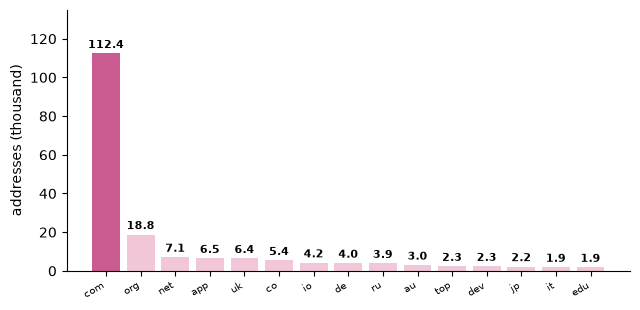

In [20]:
r = run(r"""-- Q2: top-level domains ranked by volume, with their share of phishing
SELECT TLD, COUNT(*) AS addresses, 100.0 * AVG(phishing) AS phishing_pct, RANK() OVER (ORDER BY COUNT(*) DESC) AS rank FROM ph GROUP BY 1 ORDER BY 4 LIMIT 15;""")

### Q3: how well the similarity index alone separates the classes (bands of 10 points)

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,similarity_from,addresses,phishing_pct,cumulative_pct
0,0,4002,100.000000,1.700302
1,10,8584,100.000000,5.347325
2,20,10274,100.000000,9.712368
3,30,11863,100.000000,14.752517
4,40,13515,100.000000,20.494541
5,50,14727,100.000000,26.751498
6,60,16824,100.000000,33.899392
7,70,12611,100.000000,39.257340
8,80,6254,100.000000,41.914433
9,90,1080,100.000000,42.373285


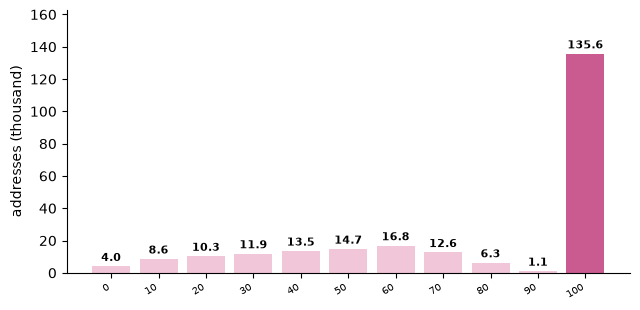

In [21]:
r = run(r"""-- Q3: how well the similarity index alone separates the classes (bands of 10 points)
SELECT CAST(FLOOR(URLSimilarityIndex / 10) * 10 AS INT) AS similarity_from, COUNT(*) AS addresses, 100.0 * AVG(phishing) AS phishing_pct,
       100.0 * SUM(COUNT(*)) OVER (ORDER BY CAST(FLOOR(URLSimilarityIndex / 10) * 10 AS INT)) / SUM(COUNT(*)) OVER () AS cumulative_pct FROM ph GROUP BY 1 ORDER BY 1;""")

### Q4: model table (numeric features and the keys needed for the splits)

- **Làm gì:** chạy truy vấn.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

In [22]:
r = run(r"""-- Q4: model table (numeric features and the keys needed for the splits)
CREATE OR REPLACE TABLE feat AS SELECT * EXCLUDE (URL) FROM ph;""")

done


### Statement 6

- **Làm gì:** chạy truy vấn, xem bảng và hình.
- **Kiểm tra:** con số có khớp với hình ở Bước 2b không.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,phishing,n
0,0,134850
1,1,100520


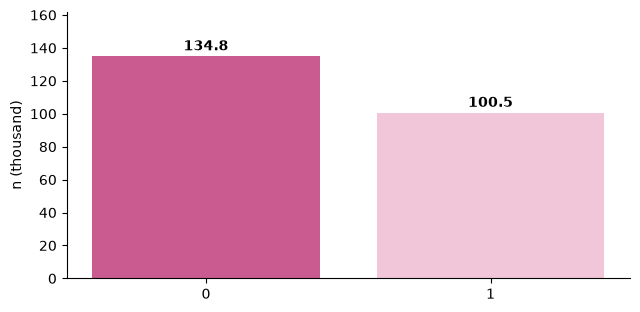

In [23]:
r = run(r"""SELECT phishing, COUNT(*) AS n FROM feat GROUP BY 1;""")

### Truy vấn bổ sung 1: hồ sơ của bảng làm việc

- **Làm gì:** `SUMMARIZE` cho biết min, max, số giá trị khác nhau và tỷ lệ thiếu của mọi cột bằng một lệnh SQL.
- **Kiểm tra:** so với bảng thống kê mô tả ở mục 2b.3.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [24]:
r = run('''SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE ph)''')

,column_name,column_type,min,max,approx_unique,null_percentage
0,URL,VARCHAR,http://0-lxshop7.45654335.xyz/hp2lebzz/kqpvi5/8/,https://zzqqw1.godaddysites.com/,261846,0.0
1,URLLength,BIGINT,13,6097,623,0.0
2,Domain,VARCHAR,0-lxshop7.45654335.xyz,zzzzzzzzzzzzzzz.hyperphp.com,247181,0.0
3,DomainLength,BIGINT,4,110,110,0.0
4,IsDomainIP,BIGINT,0,1,2,0.0
5,TLD,VARCHAR,100,zw,761,0.0
6,URLSimilarityIndex,DOUBLE,0.155574352,100.0,37997,0.0
7,CharContinuationRate,DOUBLE,0.0,1.0,759,0.0
8,TLDLegitimateProb,DOUBLE,0.0,0.5229071,466,0.0
9,URLCharProb,DOUBLE,0.001082764,0.090823664,205636,0.0


### Truy vấn bổ sung 2: các phân vị của mục tiêu

- **Làm gì:** phân vị 5%, 25%, 50%, 75%, 95% và 99% của cột mục tiêu.
- **Vì sao:** các phân vị này dùng để chọn ngưỡng, thang trục và cách cắt đuôi khi vẽ.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [25]:
r = run('''SELECT COUNT(*) AS n, MIN("phishing") AS min, QUANTILE_CONT("phishing", 0.05) AS p05, QUANTILE_CONT("phishing", 0.25) AS p25, MEDIAN("phishing") AS p50, QUANTILE_CONT("phishing", 0.75) AS p75, QUANTILE_CONT("phishing", 0.95) AS p95, QUANTILE_CONT("phishing", 0.99) AS p99, MAX("phishing") AS max FROM ph''')

,n,min,p05,p25,p50,p75,p95,p99,max
0,235370,0,0.0,0.0,0.0,1.0,1.0,1.0,1


### Truy vấn bổ sung 3: xếp hạng các nhóm

- **Làm gì:** số dòng và trung bình mục tiêu theo nhóm, xếp hạng bằng hàm cửa sổ `RANK`, kèm tỷ trọng của nhóm trong toàn bảng.
- **Vì sao:** nhóm lớn nhất và nhóm lệch nhất thường là ví dụ minh hoạ trong mục Results.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

,grp,mean_target,n,pct_of_rows,rank_by_mean
0,lol,1.0,29,0.012321,1
1,pl:443,1.0,1,0.000425,1
2,trade,1.0,9,0.003824,1
3,gq,1.0,493,0.209457,1
4,126,1.0,1,0.000425,1
5,sexy,1.0,1,0.000425,1
6,host,1.0,45,0.019119,1
7,industries,1.0,2,0.000850,1
8,repair,1.0,2,0.000850,1
9,78,1.0,31,0.013171,1


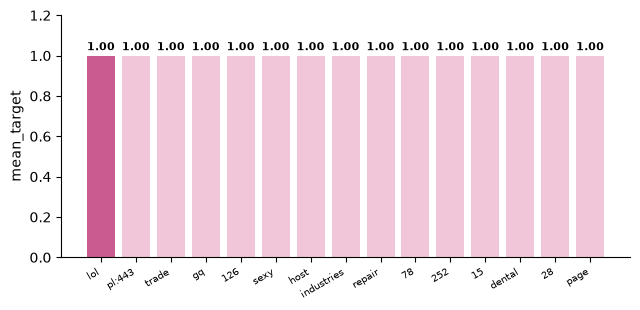

In [26]:
r = run('''SELECT CAST("TLD" AS VARCHAR) AS grp, AVG("phishing") AS mean_target, COUNT(*) AS n, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_of_rows, RANK() OVER (ORDER BY AVG("phishing") DESC) AS rank_by_mean FROM ph GROUP BY 1 ORDER BY 5 LIMIT 15''')

### Truy vấn bổ sung 4: bảng mô hình có sạch không

- **Làm gì:** kiểu dữ liệu, tỷ lệ thiếu và số giá trị khác nhau của từng cột trong bảng `feat`.
- **Kiểm tra:** cột đặc trưng nào còn thiếu thì phải xử lý trước khi sang Notebook B.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [27]:
r = run('''SELECT column_name, column_type, null_percentage, approx_unique FROM (SUMMARIZE feat) ORDER BY null_percentage DESC LIMIT 20''')

,column_name,column_type,null_percentage,approx_unique
0,URLLength,BIGINT,0.0,623
1,Domain,VARCHAR,0.0,247181
2,DomainLength,BIGINT,0.0,110
3,IsDomainIP,BIGINT,0.0,2
4,TLD,VARCHAR,0.0,761
5,URLSimilarityIndex,DOUBLE,0.0,37997
6,CharContinuationRate,DOUBLE,0.0,759
7,TLDLegitimateProb,DOUBLE,0.0,466
8,URLCharProb,DOUBLE,0.0,205636
9,TLDLength,BIGINT,0.0,13


## Bước 5. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

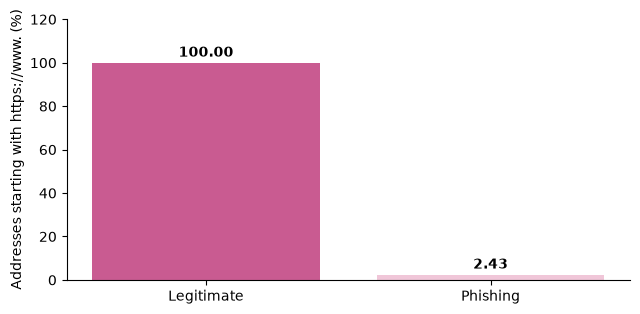

In [28]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#C95B91' if i == highlight else '#F0C6D8' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT CASE WHEN phishing = 1 THEN 'Phishing' ELSE 'Legitimate' END AS g, 100.0 * AVG(starts_https_www) AS v FROM ph GROUP BY 1 ORDER BY 1""").df()
bar_chart(fig1.g, fig1.v, 'Addresses starting with https://www. (%)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [29]:
import json, hashlib
path = 'data/processed/phishing.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n,
            'md5': hashlib.md5(open(path, 'rb').read()).hexdigest()}
json.dump(manifest, open('data/processed/manifest.json', 'w'), indent=2); print(manifest)
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/phishing.parquet', 'rows': 235370, 'columns': 58, 'feat_rows': 235370, 'md5': '3840025f21c134bebe77f5840e79186e'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta:

### Hình cho bài báo (Hình 2, 3, 4)

Vẽ lại ba hình EDA theo đúng dạng trong bài (cột nhóm, thanh ngang hai màu) từ `report/table_q1.csv`, `table_q2.csv`, `table_q3.csv` và `table_eda_correlation.csv`. Không tính lại số liệu; chỉ đọc các bảng đã lưu. Ảnh lưu thành `report/paper_fig*.png`.

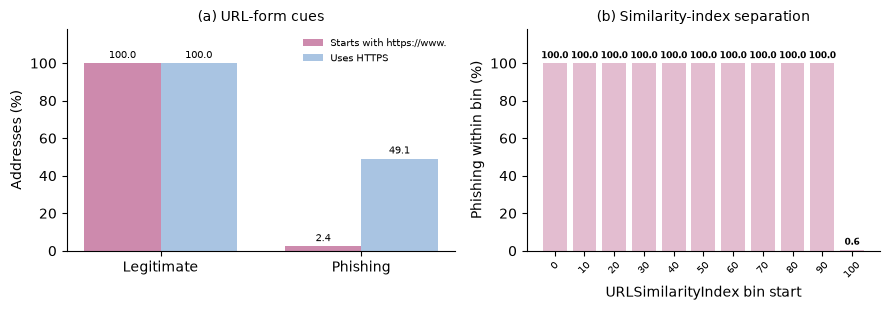

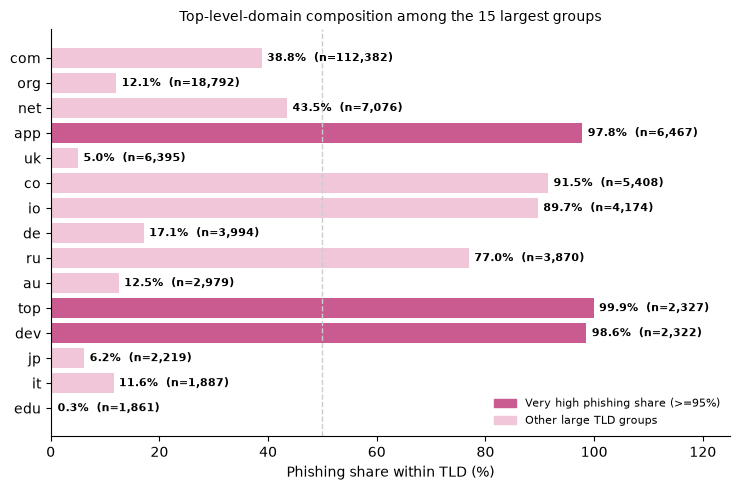

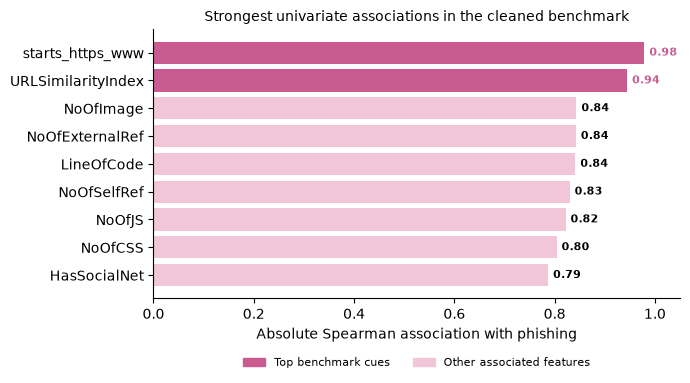

In [30]:
import matplotlib.pyplot as plt, numpy as np, pandas as pd
PINK, LPINK, BLUE = '#C95B91', '#F0C6D8', '#A9C4E2'
def clean(ax): ax.spines[['top', 'right']].set_visible(False)

# Figure 2: URL-form cues (a) and similarity-index separation (b)
q1, q3 = pd.read_csv('report/table_q1.csv').sort_values('phishing'), pd.read_csv('report/table_q3.csv')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={'width_ratios': [1.1, 1]})
x = np.arange(2); w = 0.38
for off, col, c, lab in [(-w/2, 'starts_https_www_pct', '#CD8AAD', 'Starts with https://www.'), (w/2, 'https_pct', BLUE, 'Uses HTTPS')]:
    b = ax[0].bar(x + off, q1[col], w, color=c, label=lab); ax[0].bar_label(b, fmt='%.1f', fontsize=7, padding=2)
ax[0].set_xticks(x); ax[0].set_xticklabels(['Legitimate', 'Phishing']); ax[0].set_ylabel('Addresses (%)'); ax[0].set_title('(a) URL-form cues', fontsize=10); ax[0].legend(frameon=False, fontsize=7)
b = ax[1].bar(q3.similarity_from.astype(str), q3.phishing_pct, color='#E3BDD0'); ax[1].bar_label(b, fmt='%.1f', fontsize=6.5, fontweight='bold', padding=2)
ax[1].set_xlabel('URLSimilarityIndex bin start'); ax[1].set_ylabel('Phishing within bin (%)'); ax[1].set_title('(b) Similarity-index separation', fontsize=10); ax[1].tick_params(axis='x', labelsize=7, rotation=45)
for a in ax: clean(a); a.set_ylim(0, 118)
fig.tight_layout(); fig.savefig('report/paper_fig2_url_form_cues.png', dpi=300); plt.show()

# Figure 3: phishing share inside the 15 largest top-level domains
t = pd.read_csv('report/table_q2.csv').sort_values('addresses', ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5)); high = t.phishing_pct >= 95
b = ax.barh(t.TLD, t.phishing_pct, color=np.where(high, PINK, LPINK))
for yy, (p, n) in enumerate(zip(t.phishing_pct, t.addresses)): ax.text(p + 1, yy, '%.1f%%  (n=%s)' % (p, format(int(n), ',')), va='center', fontsize=8, fontweight='bold')
ax.axvline(50, color='#CCCCCC', ls='--', lw=1); ax.set_xlim(0, 125); ax.set_xlabel('Phishing share within TLD (%)'); ax.set_title('Top-level-domain composition among the 15 largest groups', fontsize=10); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PINK), plt.Rectangle((0, 0), 1, 1, color=LPINK)], labels=['Very high phishing share (>=95%)', 'Other large TLD groups'], frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig('report/paper_fig3_tld_composition.png', dpi=300); plt.show()

# Figure 4: strongest univariate associations with the label
c = pd.read_csv('report/table_eda_correlation.csv', index_col=0).iloc[:, 0].abs()
c = c.drop([i for i in c.index if i.lower() in ('label', 'phishing')], errors='ignore').sort_values(ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4)); top2 = np.arange(len(c)) >= len(c) - 2
ax.barh(c.index, c.values, color=np.where(top2, PINK, LPINK))
for yy, v in enumerate(c.values): ax.text(v + .01, yy, '%.2f' % v, va='center', fontsize=8, fontweight='bold', color=PINK if top2[yy] else 'black')
ax.set_xlim(0, 1.05); ax.set_xlabel('Absolute Spearman association with phishing'); ax.set_title('Strongest univariate associations in the cleaned benchmark', fontsize=10); clean(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PINK), plt.Rectangle((0, 0), 1, 1, color=LPINK)], labels=['Top benchmark cues', 'Other associated features'], frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout(); fig.savefig('report/paper_fig4_univariate.png', dpi=300); plt.show()
